# Does Free Shipping Pay? · Testing Peeba's Growth Hypotheses

The companion Power BI report (*Shipping Pays the Bills*) breaks down the unit economics of Peeba, a B2B wholesale marketplace that connects international brands with retailers in Taiwan (400 orders, Jan – Jul 2023, TWD).
Its headline: **contribution margin is 19% of GMV, but without the shipping charged to retailers it falls to 0.6%.** The report ends with five hypotheses (H1–H5).
A dashboard can state hypotheses. This notebook **tests** them:

1. **How sure are we of the headline numbers?** Bootstrap confidence intervals on 400 orders.
2. **H4 · Shipping:** is the shipping charge a burden that holds retailers back, and **would free shipping pay for itself?**
3. **H1 · 0% commission orders:** what would a 5% fee do, including the risk of losing orders?
4. **Did the take rate really fall**, or did the order mix change?
5. **H2 · Peeba cash, H3 · payment fees, H5 · late payments:** what the data supports.
6. **Can each idea be A/B tested** at Peeba's volume? Power analysis and the sample size each test needs.

### Key Findings
* **Shipping really does pay the bills.** CM is 19.1% of GMV (95% CI 13.3% – 25.3%). Without the shipping margin it is **0.6% (95% CI −2.1% to +3.3%)**, with a **32% chance of being below zero**: the marketplace itself roughly breaks even.
* **Free shipping would not pay for itself.** Free shipping on every order gives up about **TWD 197K of margin a month**. The extra GMV needed to recover that is **about 30× today's**. Even free shipping only above TWD 30K needs those customers to almost **quadruple** their GMV.
* **Shipping is a burden on small orders** (40% of order value for the smallest fifth against 16% for the largest), but there is **no sign it stops new retailers from reordering**. Those who paid above-median shipping reordered *more* often (65% vs 33%, p = 0.09, n = 35).
* **The data cannot settle it, and neither can an A/B test on reorders:** detecting a 10-point lift needs about 390 new retailers per arm, or **about 100 months** at today's volume. A test on order value is feasible (about 10 months for a 20% lift).
* **Three hypotheses are supported:** 0% commission is a Direct-retailer issue, and a 5% fee would raise CM even if half that GMV left (H1). Peeba cash goes almost only to existing retailers (45 of 46 orders, H2). Late payments are mostly 1–3 days late (H5). **The fall in take rate is mostly mix:** Direct orders went from 26% to 47% of GMV.

In [ ]:
# ---- where things live -------------------------------------------------------------------------
import os, sys
from pathlib import Path
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

MAIN_FOLDERS = [Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\Radarr"),
                Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\Peeba")]
DATA_OVERRIDE = r""   # optional: full path of the interview workbook (.xlsx)

def code_folder():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "peebatools.py").exists():
            return p
    for root in [*MAIN_FOLDERS, Path.cwd()]:
        if root.exists():
            hits = sorted(root.rglob("peebatools.py"), key=lambda f: len(f.parts))
            if hits:
                return hits[0].parent
    return None

CODE = code_folder()
if CODE is None:
    raise FileNotFoundError("peebatools.py not found. Keep it next to this notebook.")
os.chdir(CODE)
sys.path.insert(0, str(CODE))
import peebatools as pt

DATA = Path(DATA_OVERRIDE) if DATA_OVERRIDE else pt.find_workbook(
    [CODE / "data", CODE, CODE.parent / "data", CODE.parent, *MAIN_FOLDERS, *[m / "data" for m in MAIN_FOLDERS]])
if DATA is None or not DATA.exists():
    raise FileNotFoundError("Workbook not found. Put the .xlsx in the data folder, or paste its full path into DATA_OVERRIDE.")

IMAGES = next((p for p in [CODE / "images", CODE.parent / "images"] if p.exists()), CODE / "images")
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

print("Code:", CODE.name, "| Data:", DATA.name, "| Images:", IMAGES.name)

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.proportion import proportion_effectsize
from peebatools import SLATE, SEA, SAND, CORAL, ORANGE, LILAC, GREY, INK, MUTED, LINE

pt.style_charts()
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

Code: pkg | Data: Finance Data Analyst Interview Project.xlsx | Images: images


## 1 · Load and Reconcile With the Dashboard

Same rules as the Power BI model: amounts in brand currency are converted to TWD with the implied rate (`item_subtotal ÷ subtotal`).
**Contribution margin (CM) = commission + shipping charged − shipping paid to brands − coupons − Peeba cash − returns − payment fees.**

In [ ]:
o = pt.load(DATA)
lines = ["gmv", "commission", "shipping_charged", "shipping_paid_to_brand", "coupons", "peeba_cash", "returns", "payment_fees", "cm", "cm_excl_shipping"]
pl = o[lines].sum().to_frame("TWD")
pl["% of GMV"] = pl.TWD / pl.loc["gmv", "TWD"]
pl.index = ["GMV", "Commission", "Shipping charged to retailers", "Shipping paid to brands", "Coupons", "Peeba cash", "Returns", "Payment fees",
            "Contribution margin", "CM excluding shipping"]
print(f"{len(o)} orders · {o.retailer_id.nunique()} retailers · {o.brand_id.nunique()} brands · {o.date.min():%d %b %Y} – {o.date.max():%d %b %Y} · as of {o.as_of.iloc[0]:%d %b %Y}")
pl.style.format({"TWD": "{:,.0f}", "% of GMV": "{:.1%}"})

400 orders · 114 retailers · 178 brands · 03 Jan 2023 – 05 Jul 2023 · as of 12 Jul 2023


,TWD,% of GMV
GMV,"6,418,755",100.0%
Commission,"839,700",13.1%
Shipping charged to retailers,"1,344,205",20.9%
Shipping paid to brands,"158,218",2.5%
Coupons,"29,822",0.5%
Peeba cash,"367,975",5.7%
Returns,"119,297",1.9%
Payment fees,"282,046",4.4%
Contribution margin,"1,226,547",19.1%
CM excluding shipping,"40,560",0.6%


## 2 · How Sure Are We of the Headline?

400 orders is a small sample, and a few large orders can move the totals. The **bootstrap** resamples the 400 orders 5,000 times and recomputes each ratio.
The spread shows how much the headline could move with a different set of orders.

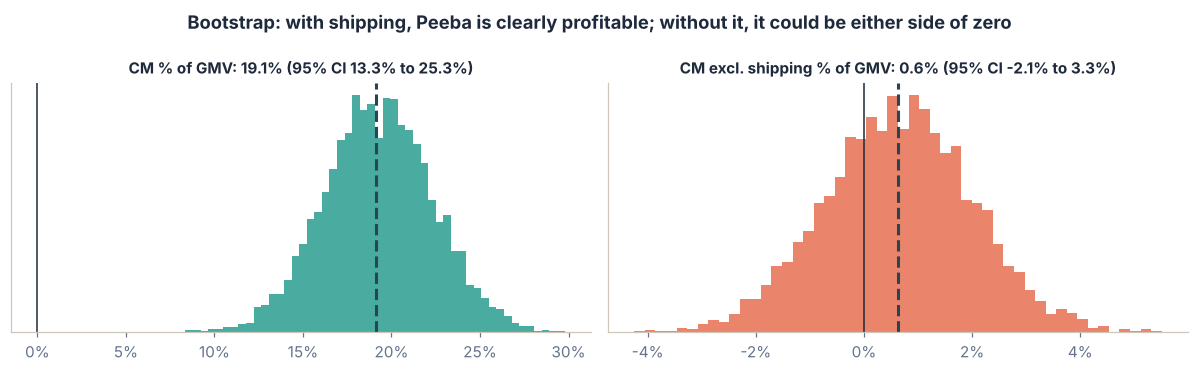

,estimate,95% CI low,95% CI high,P(below 0)
CM % of GMV,19.1%,13.3%,25.3%,0%
CM excl. shipping % of GMV,0.6%,-2.1%,3.3%,32%
Take rate (commission % of GMV),13.1%,10.9%,15.3%,0%
Shipping charged % of GMV,20.9%,16.8%,25.4%,0%


In [ ]:
ratios = {
    "CM % of GMV": lambda x: x.cm.sum() / x.gmv.sum(),
    "CM excl. shipping % of GMV": lambda x: x.cm_excl_shipping.sum() / x.gmv.sum(),
    "Take rate (commission % of GMV)": lambda x: x.commission.sum() / x.gmv.sum(),
    "Shipping charged % of GMV": lambda x: x.shipping_charged.sum() / x.gmv.sum(),
}
boot = {k: pt.bootstrap(o, f, n=5000) for k, f in ratios.items()}
ci = pd.DataFrame({k: {"estimate": ratios[k](o), "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5),
                       "P(below 0)": (v < 0).mean()} for k, v in boot.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, k, c in [(axes[0], "CM % of GMV", SEA), (axes[1], "CM excl. shipping % of GMV", CORAL)]:
    v = boot[k]
    ax.hist(v, bins=50, color=c, alpha=0.85)
    ax.axvline(0, color=INK, lw=1)
    ax.axvline(ratios[k](o), color=SLATE, lw=2, ls="--")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.set_yticks([])
    ax.set_title(f"{k}: {ratios[k](o):.1%} (95% CI {np.percentile(v, 2.5):.1%} to {np.percentile(v, 97.5):.1%})", fontsize=10)
fig.suptitle("Bootstrap: with shipping, Peeba is clearly profitable; without it, it could be either side of zero", fontweight="bold", color=INK)
plt.tight_layout(); save(fig, "bootstrap margins"); plt.show()
ci.style.format({"estimate": "{:.1%}", "95% CI low": "{:.1%}", "95% CI high": "{:.1%}", "P(below 0)": "{:.0%}"})

**Reading the Intervals**
* **CM of 19.1%** is solid: even the low end of the interval (13.3%) is comfortably positive.
* **CM excluding shipping (0.6%)** could easily be negative: the interval runs from −2.1% to +3.3%, and 32% of resamples are below zero. Commission (13.1%) barely covers incentives, returns and payment fees.
* **Shipping charged is 20.9% of GMV (16.8% – 25.4%).** That is more than the commission, which is why the next section looks at shipping first.

## 3 · H4 · Shipping: Burden or Profit Engine?

### 3.1 Who Pays the Most Shipping?

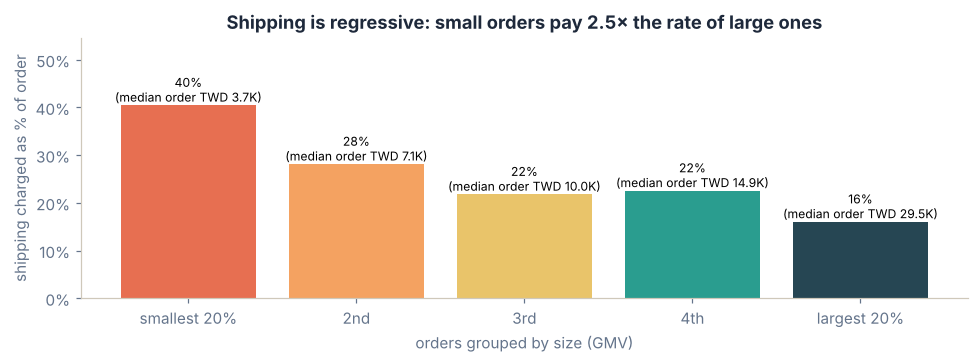

Spearman correlation between order size and shipping %: rho = -0.21, p = 1.5e-05


In [ ]:
o["size_band"] = pd.qcut(o.gmv, 5, labels=["smallest 20%", "2nd", "3rd", "4th", "largest 20%"])
burden = o.groupby("size_band").agg(orders=("gmv", "size"), median_order=("gmv", "median"),
                                    shipping_pct=("shipping_pct", "median"), free_shipping=("shipping_charged", lambda s: (s == 0).mean()))
rho, p_rho = stats.spearmanr(o.gmv, o.shipping_pct)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(burden.index.astype(str), burden.shipping_pct, color=[CORAL, ORANGE, SAND, SEA, SLATE])
for i, (v, m) in enumerate(zip(burden.shipping_pct, burden.median_order)):
    ax.text(i, v + 0.008, f"{v:.0%}\n(median order TWD {m / 1e3:,.1f}K)", ha="center", fontsize=8)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, burden.shipping_pct.max() * 1.35)
ax.set_xlabel("orders grouped by size (GMV)"); ax.set_ylabel("shipping charged as % of order")
ax.set_title(f"Shipping is regressive: small orders pay {burden.shipping_pct.iloc[0] / burden.shipping_pct.iloc[-1]:.1f}× the rate of large ones")
plt.tight_layout(); save(fig, "shipping burden"); plt.show()
print(f"Spearman correlation between order size and shipping %: rho = {rho:.2f}, p = {p_rho:.1e}")

### 3.2 Do High Shipping Charges Stop New Retailers From Coming Back?

If shipping were a real barrier, new retailers who paid a high shipping share on their first orders should reorder less often.
The test uses retailers whose **first order month is Jan–Apr 2023**, so each has at least two months to reorder within the data.

In [ ]:
first_month = o.first_order_month.dt.to_period("M")
newr = o[(first_month == o.date.dt.to_period("M")) & (first_month >= pd.Period("2023-01", "M")) & (first_month <= pd.Period("2023-04", "M"))]
later = o[o.date.dt.to_period("M") > first_month]
cohort = newr.groupby("retailer_id").agg(first_gmv=("gmv", "sum"), first_shipping=("shipping_charged", "sum"), type=("retailer_type", "first"))
cohort["shipping_pct"] = cohort.first_shipping / cohort.first_gmv
cohort["reordered"] = cohort.index.isin(later.retailer_id)
cohort["high_shipping"] = cohort.shipping_pct > cohort.shipping_pct.median()
tab = pd.crosstab(cohort.high_shipping, cohort.reordered)
odds, p_fisher = stats.fisher_exact(tab)
u, p_mw = stats.mannwhitneyu(cohort[cohort.reordered].shipping_pct, cohort[~cohort.reordered].shipping_pct, alternative="two-sided")
rates = cohort.groupby("high_shipping").reordered.agg(["mean", "size"]).rename(index={False: "below-median shipping %", True: "above-median shipping %"})
print(f"New retailers Jan–Apr 2023: {len(cohort)} · reordered later: {cohort.reordered.mean():.0%}")
print(rates.rename(columns={"mean": "reorder rate", "size": "retailers"}).assign(**{"reorder rate": lambda x: x["reorder rate"].map("{:.0%}".format)}).to_string())
print(f"Fisher exact test p = {p_fisher:.2f} · Mann-Whitney (shipping % of reorderers vs not) p = {p_mw:.2f}")

New retailers Jan–Apr 2023: 35 · reordered later: 49%
                        reorder rate  retailers
high_shipping                                  
below-median shipping %          33%         18
above-median shipping %          65%         17
Fisher exact test p = 0.09 · Mann-Whitney (shipping % of reorderers vs not) p = 0.19


**Reading the Test**
* **The effect points the other way.** New retailers who paid **above-median** shipping on their first orders reordered **65%** of the time, against **33%** for those who paid less. The difference is not significant (Fisher p = 0.09, Mann-Whitney p = 0.19), but it gives **no support** to the idea that shipping charges drive retailers away.
* A likely explanation: retailers who order small, frequent top-ups pay a high shipping share *and* reorder often, so the shipping share mostly reflects the buying pattern.
* With only 35 new retailers this is weak evidence either way. What it rules out is a large deterrent effect.

### 3.3 What Would Free Shipping Cost and What Would It Need to Earn?

Free shipping for orders above a threshold gives up the shipping charged on those orders. To break even, those customers must bring **extra GMV**,
and each extra TWD of GMV only earns the **CM excluding shipping** of such orders (the shipping on the new orders would be free too).

In [ ]:
months = (o.date.max() - o.date.min()).days / 30.44
rows = []
for thr in [0, 10_000, 20_000, 30_000, 50_000]:
    s = o[o.gmv >= thr]
    lost = s.shipping_charged.sum() - s.shipping_paid_to_brand.sum()
    margin = s.cm_excl_shipping.sum() / s.gmv.sum()
    rows.append((f"all orders" if thr == 0 else f"orders ≥ TWD {thr / 1e3:,.0f}K", len(s) / len(o), lost, lost / months,
                 margin, (lost / margin) / s.gmv.sum() if margin > 0 else np.inf))
free = pd.DataFrame(rows, columns=["free shipping for", "share of orders", "shipping margin given up", "per month", "CM excl. shipping % on those orders",
                                   "extra GMV needed (× their current GMV)"]).set_index("free shipping for")
free.style.format({"share of orders": "{:.0%}", "shipping margin given up": "TWD {:,.0f}", "per month": "TWD {:,.0f}",
                   "CM excl. shipping % on those orders": "{:.1%}", "extra GMV needed (× their current GMV)": lambda v: "never pays back" if not np.isfinite(v) else f"+{v:.0%}"})

,share of orders,shipping margin given up,per month,CM excl. shipping % on those orders,extra GMV needed (× their current GMV)
free shipping for,,,,,
all orders,100%,"TWD 1,185,987","TWD 197,276",0.6%,+2924%
orders ≥ TWD 10K,50%,"TWD 835,122","TWD 138,913",1.6%,+997%
orders ≥ TWD 20K,20%,"TWD 470,039","TWD 78,186",3.1%,+434%
orders ≥ TWD 30K,10%,"TWD 263,172","TWD 43,776",3.8%,+273%
orders ≥ TWD 50K,4%,"TWD 90,537","TWD 15,060",2.0%,+264%


**Reading the Table**
* **Free shipping on everything** gives up about TWD 1.19M over the period (about **TWD 197K a month**). Without shipping, an extra TWD of GMV earns only 0.6% CM, so GMV would need to grow by about **2,900% (30×)** to break even.
* **Thresholds help, but not enough.** Free shipping on orders ≥ TWD 30K affects 10% of orders and costs about TWD 44K a month. Those orders earn 3.8% CM without shipping, so they would need to grow by **+273%** to pay back.
* **Verdict on H4:** as long as commission barely covers incentives and fees, shipping is the profit engine and should be **protected, not given away**. Free-shipping promotions only make sense if brands fund them, or for retention cases with a clear lifetime value.

### 3.4 Could fFree Shipping Even be A/B Tested?

A power analysis asks how many units each arm of an experiment needs to detect a realistic effect (5% significance, 80% power).

In [ ]:
power_p, power_t = NormalIndPower(), TTestIndPower()
new_per_month = o[o.new_retailer].retailer_id.nunique() / months
orders_per_month = len(o) / months
base_reorder = cohort.reordered.mean()
log_sd = np.log(o.gmv).std()
designs = []
for lift in (0.05, 0.10, 0.20):
    n = power_p.solve_power(proportion_effectsize(min(base_reorder + lift, 0.99), base_reorder), alpha=0.05, power=0.8)
    designs.append(("reorder rate of new retailers", f"{base_reorder:.0%} → {base_reorder + lift:.0%}", n, "new retailers", 2 * n / new_per_month))
for lift in (0.10, 0.20, 0.30):
    n = power_t.solve_power(np.log(1 + lift) / log_sd, alpha=0.05, power=0.8)
    designs.append(("order value (log GMV)", f"+{lift:.0%}", n, "orders", 2 * n / orders_per_month))
power = pd.DataFrame(designs, columns=["metric", "effect to detect", "needed per arm", "unit", "months at current volume"])
print(f"Current volume: about {orders_per_month:.0f} orders and {new_per_month:.1f} new retailers a month.")
power.style.hide(axis="index").format({"needed per arm": "{:,.0f}", "months at current volume": "{:,.1f}"})

Current volume: about 67 orders and 7.8 new retailers a month.


metric,effect to detect,needed per arm,unit,months at current volume
reorder rate of new retailers,49% → 54%,"1,568",new retailers,401.1
reorder rate of new retailers,49% → 59%,389,new retailers,99.5
reorder rate of new retailers,49% → 69%,94,new retailers,24.0
order value (log GMV),+10%,"1,223",orders,36.8
order value (log GMV),+20%,335,orders,10.1
order value (log GMV),+30%,162,orders,4.9


**Reading the Power Analysis**
* Peeba gets about **8 new retailers a month**. Detecting a 10-point lift in the reorder rate (49% → 59%) needs **389 new retailers per arm: about 100 months**. Even a 20-point lift needs 2 years. **A free-shipping test on retention is not feasible at this scale.**
* **Order value is a better test metric.** With about 67 orders a month, a 20% lift in order value needs 335 orders per arm (about 10 months), and a 30% lift needs about 5 months.
* This kind of check belongs *before* any experiment. It turns "let's A/B test it" into a realistic plan.

## 4 · H1 · Should Direct Orders Pay a Commission?

Direct retailers are the brand's own customers ordering through Peeba. The dashboard found that 28.5% of GMV pays 0% commission. Is that really a Direct effect?

commission_pct   0% commission  commission charged
retailer_source                                   
Direct                      51                  40
Marketplace                  3                 306
Fisher exact test (Direct vs Marketplace, 0% commission): p = 1.6e-35
Direct 0% orders: 51 orders, TWD 1.79M GMV (28% of GMV), CM TWD -123K


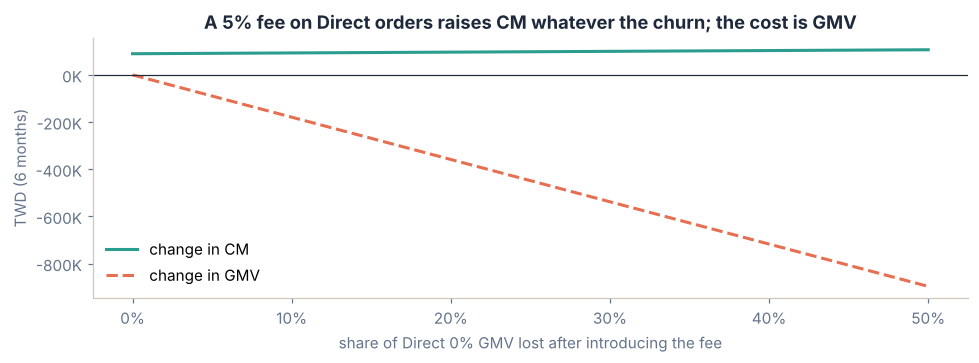

With no lost orders, a 5% fee adds TWD 90K of CM over the period. These orders currently lose TWD 123K in CM,
so even if 50% of that GMV left, CM would still rise by TWD 106K.


In [ ]:
zero = o.commission_pct == 0
src = pd.crosstab(o.retailer_source, zero.map({True: "0% commission", False: "commission charged"}))
_, p_src = stats.fisher_exact(pd.crosstab(o.retailer_source, zero))
dz = o[(o.retailer_source == "Direct") & zero]
print(src.to_string())
print(f"Fisher exact test (Direct vs Marketplace, 0% commission): p = {p_src:.1e}")
print(f"Direct 0% orders: {len(dz)} orders, {pt.twd(dz.gmv.sum())} GMV ({dz.gmv.sum() / o.gmv.sum():.0%} of GMV), CM {pt.twd(dz.cm.sum())}")

FEE = 0.05
loss = np.linspace(0, 0.5, 51)
gain = FEE * dz.gmv.sum()
cm_after = (1 - loss) * (dz.cm.sum() + gain)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(loss, cm_after - dz.cm.sum(), color=SEA, lw=2, label="change in CM")
ax.plot(loss, -loss * dz.gmv.sum(), color=CORAL, lw=2, ls="--", label="change in GMV")
ax.axhline(0, color=INK, lw=0.8)
ax.xaxis.set_major_formatter(pct); ax.set_xlabel("share of Direct 0% GMV lost after introducing the fee")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}K")); ax.set_ylabel("TWD (6 months)")
ax.legend(frameon=False); ax.set_title("A 5% fee on Direct orders raises CM whatever the churn; the cost is GMV")
plt.tight_layout(); save(fig, "direct fee"); plt.show()
print(f"With no lost orders, a {FEE:.0%} fee adds {pt.twd(gain)} of CM over the period. These orders currently lose {pt.twd(-dz.cm.sum())} in CM,")
print(f"so even if 50% of that GMV left, CM would still rise by {pt.twd(cm_after[-1] - dz.cm.sum())}.")

**Reading H1**
* **0% commission is almost entirely a Direct-retailer phenomenon:** 51 of 54 zero-commission orders are Direct (Fisher p < 10⁻³⁴). Those 51 orders are **28% of GMV** and together **lose TWD 123K** of CM, because Peeba still pays incentives and fees on them.
* **A 5% fee raises CM whatever happens to volume.** With no lost orders it adds about TWD 90K over the period. Because these orders currently lose money, losing some of them *also* raises CM: even if half the GMV left, CM would still rise by about TWD 106K.
* **The real trade-off is GMV, not margin.** Losing 20% of Direct 0% GMV would cost about TWD 360K of GMV. Whether that is acceptable depends on how Peeba values GMV growth against profitability, and that is the question a commission test should answer.

## 5 · Did the Take Rate Really Fall or Did the Mix Change?

The dashboard shows the take rate falling from about 15% in January to about 9% in April. Two very different stories could explain that:
Peeba charging less on the same kind of orders, or **more 0% Direct orders in the mix**. A permutation test compares Jan–Feb with Mar–Jun, overall and for Marketplace orders only.

In [ ]:
tw = o[o.date < "2023-07-01"].copy()   # July holds only two orders
tw["period"] = np.where(tw.date < "2023-03-01", "Jan–Feb", "Mar–Jun")
def take(x):
    return x.commission.sum() / x.gmv.sum()

def perm_test(df, n=5000, seed=3):
    rng = np.random.default_rng(seed)
    a, b = df[df.period == "Jan–Feb"], df[df.period == "Mar–Jun"]
    obs = take(b) - take(a)
    lab = df.period.values.copy()
    diffs = []
    for _ in range(n):
        rng.shuffle(lab)
        diffs.append(take(df[lab == "Mar–Jun"]) - take(df[lab == "Jan–Feb"]))
    return take(a), take(b), obs, (np.abs(diffs) >= abs(obs)).mean()

rows = []
for name, df in [("All orders", tw), ("Marketplace only", tw[tw.retailer_source == "Marketplace"]), ("Direct only", tw[tw.retailer_source == "Direct"])]:
    a_, b_, obs, p = perm_test(df)
    rows.append((name, a_, b_, obs, p))
tr = pd.DataFrame(rows, columns=["orders", "take rate Jan–Feb", "take rate Mar–Jun", "change (pp)", "permutation p"]).set_index("orders")
mix = tw.groupby("period").apply(lambda x: x[x.retailer_source == "Direct"].gmv.sum() / x.gmv.sum())
print(f"Direct share of GMV: Jan–Feb {mix['Jan–Feb']:.0%} → Mar–Jun {mix['Mar–Jun']:.0%}")
tr.style.format({"take rate Jan–Feb": "{:.1%}", "take rate Mar–Jun": "{:.1%}", "change (pp)": lambda v: f"{v * 100:+.1f}", "permutation p": "{:.3f}"})

Direct share of GMV: Jan–Feb 26% → Mar–Jun 47%


,take rate Jan–Feb,take rate Mar–Jun,change (pp),permutation p
orders,,,,
All orders,16.2%,11.8%,-4.4,0.061
Marketplace only,19.1%,17.5%,-1.6,0.025
Direct only,8.0%,5.3%,-2.7,0.516


**Reading the Test**
* The overall take rate fell **4.4 points** (16.2% → 11.8%), but that drop is not significant (p = 0.06), because a few large orders dominate.
* **Most of the fall is mix:** Direct orders, which mostly pay 0%, went from **26% to 47% of GMV**. Within Marketplace orders the take rate dipped only **1.6 points** (19.1% → 17.5%, p = 0.03), which is a real but small decline.
* So the take-rate problem is mainly **which retailers are ordering**, and that points straight back to H1.

## 6 · H2 · Who Gets Peeba Cash?

In [ ]:
cash = o.peeba_cash > 0
ct = pd.crosstab(cash.map({True: "orders with Peeba cash", False: "orders without"}), o.new_retailer.map({True: "new retailer", False: "repeat retailer"}))
_, p_cash = stats.fisher_exact(pd.crosstab(cash, o.new_retailer))
by_type = o.groupby("retailer_type").agg(orders=("gmv", "size"), gmv=("gmv", "sum"), peeba_cash=("peeba_cash", "sum"), cm=("cm", "sum"))
by_type["share of all Peeba cash"] = by_type.peeba_cash / by_type.peeba_cash.sum()
by_type["CM % of GMV"] = by_type.cm / by_type.gmv
by_type["CM % before cash"] = (by_type.cm + by_type.peeba_cash) / by_type.gmv
print(ct.to_string())
print(f"Fisher exact test (cash vs new/repeat): p = {p_cash:.4f}")
by_type.sort_values("peeba_cash", ascending=False).style.format({"orders": "{:,}", "gmv": "{:,.0f}", "peeba_cash": "{:,.0f}", "cm": "{:,.0f}",
    "share of all Peeba cash": "{:.0%}", "CM % of GMV": "{:.1%}", "CM % before cash": "{:.1%}"})

new_retailer            new retailer  repeat retailer
peeba_cash                                           
orders with Peeba cash             1               45
orders without                    75              279
Fisher exact test (cash vs new/repeat): p = 0.0006


,orders,gmv,peeba_cash,cm,share of all Peeba cash,CM % of GMV,CM % before cash
retailer_type,,,,,,,
Social Media,62,"763,914","291,512","-73,422",79%,-9.6%,28.5%
Online Store,232,"3,237,295","44,764","1,047,754",12%,32.4%,33.7%
Brick And Mortar,99,"1,676,347","31,698","336,701",9%,20.1%,22.0%
Pop Up Store,7,"741,199",0,"-84,485",0%,-11.4%,-11.4%


**Reading H2**
* **Peeba cash almost never goes to new retailers:** 45 of 46 orders with cash came from existing retailers (Fisher p = 0.0006). As an acquisition tool it is not being used.
* **79% of all Peeba cash goes to social-media retailers.** Before cash, their orders earn 28.5% CM, the highest of any type. After cash they *lose* 9.6%. The incentive turns the best-margin segment into a loss-maker.
* The hypothesis is supported. The next step is an incentive test on existing social-media retailers, measured on 90-day GMV, to see how much of their volume the cash actually buys.

## 7 · H3 · Moving Large Invoices Off Card Payments

In [ ]:
BANK_FEE = 0.005   # assumed cost of a bank transfer / virtual account, as % of the invoice
rows = []
for thr in (10_000, 30_000, 50_000):
    s = o[o.receivable >= thr]
    saving = s.fee_collection.sum() - BANK_FEE * s.receivable.clip(lower=0).sum()
    rows.append((f"invoices ≥ TWD {thr / 1e3:,.0f}K", len(s), s.receivable.clip(lower=0).sum() / o.receivable.clip(lower=0).sum(), s.fee_collection.sum(),
                 saving, saving / months * 12))
fees = pd.DataFrame(rows, columns=["move to bank transfer", "orders", "share of receivables", "card fees today", "saving (period)", "saving per year"]).set_index("move to bank transfer")
print(f"Card (Stripe) fees are {o.fee_collection.sum() / o.gmv.sum():.1%} of GMV; payout (Airwallex) fees {o.fee_payout.sum() / o.gmv.sum():.1%}.")
fees.style.format({"orders": "{:,}", "share of receivables": "{:.0%}", "card fees today": "TWD {:,.0f}", "saving (period)": "TWD {:,.0f}", "saving per year": "TWD {:,.0f}"})

Card (Stripe) fees are 3.3% of GMV; payout (Airwallex) fees 1.1%.


,orders,share of receivables,card fees today,saving (period),saving per year
move to bank transfer,,,,,
invoices ≥ TWD 10K,223,86%,"TWD 184,241","TWD 152,908","TWD 305,214"
invoices ≥ TWD 30K,51,46%,"TWD 97,727","TWD 81,106","TWD 161,894"
invoices ≥ TWD 50K,20,29%,"TWD 61,888","TWD 51,363","TWD 102,524"


**Reading H3**
* Card (Stripe) fees are **3.3% of GMV**, the largest fee line.
* Moving invoices **≥ TWD 30K** (51 orders, 46% of receivables) to bank transfer at an assumed 0.5% saves about **TWD 81K over the period, about TWD 162K a year**. Going down to TWD 10K roughly doubles that.
* This is the easiest win: it needs no change in retailer behaviour beyond the payment method for large invoices.

## 8 · H5 · Are Late Payments Only a Few Days Late?

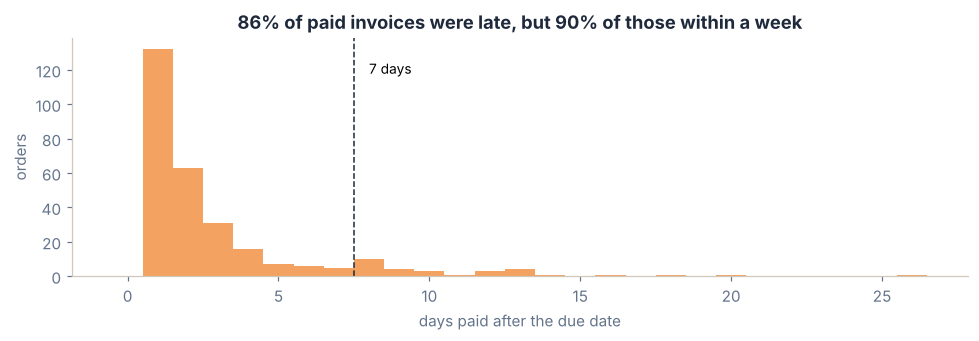

Late payers: median 2 days late (95% CI 1–2); 78% within 3 days.
Lateness vs invoice size: Spearman rho = -0.07 (p = 0.24); by retailer type: Kruskal-Wallis p = 0.27
Still unpaid and overdue: 16 invoices, TWD 174K, 28 days past due (median).


In [ ]:
paid = o[o.paid_date.notna()]
late = paid[paid.days_late > 0]
med_boot = pt.bootstrap(late, lambda x: x.days_late.median(), n=3000)
open_overdue = o[o.receivable_status == "Overdue"]
rho_l, p_l = stats.spearmanr(late.receivable, late.days_late)
kw = stats.kruskal(*[g.days_late.values for _, g in late.groupby("retailer_type") if len(g) >= 5])

fig, ax = plt.subplots(figsize=(9, 3.2))
bins = np.arange(0, late.days_late.max() + 2) - 0.5
ax.hist(late.days_late, bins=bins, color=ORANGE)
ax.axvline(7.5, color=INK, ls="--", lw=1); ax.text(8, ax.get_ylim()[1] * 0.85, "7 days", fontsize=9)
ax.set_xlabel("days paid after the due date"); ax.set_ylabel("orders")
ax.set_title(f"{len(late) / len(paid):.0%} of paid invoices were late, but {(late.days_late <= 7).mean():.0%} of those within a week")
plt.tight_layout(); save(fig, "late payments"); plt.show()
print(f"Late payers: median {late.days_late.median():.0f} days late (95% CI {np.percentile(med_boot, 2.5):.0f}–{np.percentile(med_boot, 97.5):.0f}); "
      f"{(late.days_late <= 3).mean():.0%} within 3 days.")
print(f"Lateness vs invoice size: Spearman rho = {rho_l:.2f} (p = {p_l:.2f}); by retailer type: Kruskal-Wallis p = {kw.pvalue:.2f}")
print(f"Still unpaid and overdue: {len(open_overdue)} invoices, {pt.twd(open_overdue.receivable.sum())}, "
      f"{(o.as_of.iloc[0] - open_overdue.due_date).dt.days.median():.0f} days past due (median).")

**Reading H5**
* **86% of paid invoices were paid after the due date**, but the **median delay is 2 days** (95% CI 1–2), and 78% arrive within 3 days. Lateness is not linked to invoice size or retailer type.
* That looks like a **process habit** (paying on receipt of a reminder) rather than credit risk, so H5 is supported: **automated reminders 3 days before the due date** should remove most of the delay.
* The real credit risk is small but different: **16 invoices (TWD 174K) are still unpaid, a median 28 days past due**. They need collection follow-up, not reminders.

## 9 · Verdict

| Hypothesis | Test | Result | Verdict | Next step |
|---|---|---|---|---|
| **H4** Shipping carries the margin; free shipping? | Bootstrap CI, break-even, Fisher test on reorders, power analysis | CM without shipping 0.6% (32% chance < 0); free shipping needs ~30× GMV; no sign shipping deters reorders | **Supported: protect shipping**, no free shipping | Get true freight cost; any test should use order value, not reorders |
| **H1** 0% Direct orders could pay a fee | Fisher test, fee simulation | 51 of 54 zero-commission orders are Direct; they lose TWD 123K; a 5% fee raises CM even with 50% churn | **Supported** | Commission test on a sample of Direct brands, tracking GMV |
| Take rate is falling | Permutation test, mix split | Mostly mix (Direct 26% → 47% of GMV); Marketplace −1.6 pts | **Mix, not price** | Report take rate by source |
| **H2** Peeba cash subsidises existing retailers | Fisher test, CM by type | 45 of 46 cash orders are repeat; 79% to social media, whose CM turns −9.6% | **Supported** | Incentive holdout test on social-media repeaters |
| **H3** Card fees on large invoices | Fee simulation | ~TWD 162K a year saved at the TWD 30K threshold | **Supported (assumed bank fee 0.5%)** | Pilot bank transfer for large invoices |
| **H5** Late payments are only a few days late | Bootstrap median, Spearman, Kruskal-Wallis | Median 2 days, 78% within 3 days, no link to size or type | **Supported** | Reminder 3 days before the due date; collect the 16 overdue invoices |

### Limitations
* **400 orders over six months** is a small sample, and many tests have little power. "Not significant" here often means "not enough data", not "no effect".
* **True freight cost is missing.** Shipping charged to retailers is treated as margin, minus what Peeba pays back to brands. If Peeba pays carriers separately, the shipping margin (and the 19% CM) is overstated.
* All comparisons are **observational**. Retailers who pay more shipping, receive Peeba cash, or order Direct differ in other ways too. Only a controlled test can show cause and effect.
* Bank-transfer fees (0.5%) are an assumption.